In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import math

In [2]:
clinical_data = pd.read_csv("datasets/clinical_data.csv")
lab_data1 = pd.read_csv("datasets/lab_data.csv")

Filtering data for 30 days

In [3]:
preop = lab_data1[(lab_data1['dt'] < 0) & (lab_data1['dt'] >= -2592000)] #30 days

preop_last = (preop.sort_values('dt').groupby(['caseid', 'name']).last()   
              .reset_index()[['caseid','dt', 'name', 'result']])

preop_last.head(10)
print("pre-op rows:", len(preop))

pre-op rows: 196862


In [4]:
preop.groupby("name")["dt"].describe()
print("median hours before surgery:", (preop_last["dt"].abs()/3600).median())

median hours before surgery: 29.634444444444444


In [5]:
lab_data = (preop_last
            .pivot(index="caseid", columns="name", values="result")
            .reset_index())
lab_data.columns.name = None

lab_cols = [c for c in lab_data.columns if c != "caseid"]
lab_data[lab_cols] = lab_data[lab_cols].apply(pd.to_numeric, errors="coerce")

lab_data.head(10)
print(lab_data.shape)
print(clinical_data.shape)

(5388, 35)
(6388, 74)


filtering columns that have more than 75 missing data

In [6]:
missing_rate = lab_data.isna().mean()
lab_data = lab_data.loc[:, missing_rate < 0.75]
print("after 75% filter:", lab_data.shape)
lab_data


after 75% filter: (5388, 24)


,caseid,alb,alt,aptt,ast,bun,cl,cr,crp,fib,...,k,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc
0,1,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,...,3.5,141.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,NaN,NaN,NaN,NaN,NaN,115.0,NaN,NaN,NaN,...,4.7,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36
2,4,NaN,NaN,NaN,NaN,NaN,108.0,NaN,NaN,NaN,...,4.3,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5,4.6,30.0,36.5,64.0,27.0,108.0,1.83,NaN,178.0,...,4.9,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64
4,6,3.9,17.0,29.1,19.0,14.0,104.0,1.07,0.01,183.0,...,3.4,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5383,6384,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.2,143.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5384,6385,3.7,28.0,NaN,18.0,19.0,109.0,0.84,NaN,NaN,...,4.0,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45
5385,6386,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.5,142.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5386,6387,4.4,10.0,32.2,16.0,7.0,103.0,0.65,0.03,239.0,...,3.6,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70


Remove physiologically impossible values only

In [7]:
lab_data = lab_data[lab_data["hct"].between(10, 65) | lab_data["hct"].isna()]
for c in ["height", "weight", "bmi"]:
    clinical_data.loc[clinical_data[c] <= 0, c] = np.nan
print("lab_data after plausibility filter:", lab_data.shape)
print("clinical_data after plausibility filter:", clinical_data.shape)

lab_data after plausibility filter: (5388, 24)
clinical_data after plausibility filter: (6388, 74)


Fix the syntax error in data

In [8]:
clinical_data["age"] = clinical_data["age"].replace(">89", 90)
clinical_data["age"] = pd.to_numeric(clinical_data["age"], errors="coerce")

Merge 2 dataframes with common IDs

In [9]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")

In [10]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")
merged_data["sex_bin"] = (merged_data["sex"] == "M").astype(int)

predictors = ["sex_bin", "age", "height", "weight", "bmi"]

results = []
for col in predictors:
    sub = merged_data[[col, "hct"]].dropna()   # pairwise deletion, like .corr()
    r, p = pearsonr(sub[col], sub["hct"])
    results.append({"variable": col, "pearson_r": r, "p_value": p, "n": len(sub)})

corr_df = pd.DataFrame(results)
print(corr_df)

  variable  pearson_r        p_value     n
0  sex_bin   0.241466   5.681913e-56  4138
1      age  -0.061301   7.950962e-05  4138
2   height   0.257384   1.323553e-63  4138
3   weight   0.365879  2.846304e-131  4138
4      bmi   0.265882   6.616834e-68  4138


This is the dataframe on which we will build our ML models

In [11]:
merged_data = merged_data.dropna(subset=['hct','sex_bin','height','weight','bmi'])
merged_data


,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc,sex_bin
1,2,2487,0,15741,-1039,14921.000000,1721,14621,-221160,1506840,...,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36,1
3,5,4416,0,21531,-1009,22391.000000,2591,20291,-67560,3734040,...,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64,1
4,6,5586,0,5145,-51,4749.000000,2649,4449,-300600,131400,...,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20,0
5,7,5124,0,15770,477,14817.000000,3177,14577,-154320,623280,...,139.0,NaN,229.0,109.0,0.95,10.8,0.4,7.4,4.28,0
8,11,3963,0,5265,-222,5117.999999,618,4518,-135540,37260,...,141.0,NaN,261.0,121.0,0.90,10.2,0.3,5.8,6.31,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5381,6382,5436,0,6876,-136,6764.000000,764,5864,-227820,204180,...,141.0,3.2,323.0,111.0,0.94,10.7,0.9,6.9,5.22,0
5382,6383,4255,0,23242,-1883,23137.000000,3037,22641,-224040,812760,...,141.0,4.8,202.0,114.0,0.92,10.5,0.6,6.5,5.01,1
5384,6385,2278,0,20643,-544,20996.000000,2396,19496,-225600,1675200,...,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45,1
5386,6387,5230,0,12025,-550,12830.000000,1730,11030,-227760,377040,...,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70,0


## Model Implementation

import and settings

In [12]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42  
FEATURES = ["bmi", "height", "sex_bin", "weight"]
TARGET = "hct"

Train/Test split
| Right now, 80% train (tuning and 5-fold cv) and 20% test

In [13]:
model_df = merged_data.dropna(subset=FEATURES + [TARGET]).copy()
X, y = model_df[FEATURES], model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("total:", len(model_df), "| train:", len(X_train), "| test:", len(X_test))

total: 4138 | train: 3310 | test: 828


Base Model

In [14]:
def cv_summary(name, est):
    s = cross_validate(est, X_train, y_train, cv=cv,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    return {"model": name,
            "CV R2 mean": s["test_r2"].mean(), "CV R2 std": s["test_r2"].std(),
            "CV RMSE mean": -s["test_rmse"].mean()}

base_table = pd.DataFrame([
    cv_summary("Mean predictor (dummy)", DummyRegressor(strategy="mean")),
    cv_summary("Linear regression (OLS)", LinearRegression()),
])
base_table

,model,CV R2 mean,CV R2 std,CV RMSE mean
0,Mean predictor (dummy),-0.003544,0.004958,5.474899
1,Linear regression (OLS),0.141172,0.021103,5.063877


Polynomial pipeline

In [15]:
poly_pipe = Pipeline([
    ("scale_in", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scale_poly", StandardScaler()),
    ("ridge", Ridge()),
])

Hyper parameter search

In [16]:
param_grid = {
    "poly__degree": [1, 2, 3, 4],
    "ridge__alpha": np.logspace(-2, 4, 13),
}

grid = GridSearchCV(
    poly_pipe, param_grid, cv=cv,
    scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
    refit="r2", return_train_score=True, n_jobs=-1,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV R2: {grid.best_score_:.4f}")

Best parameters: {'poly__degree': 2, 'ridge__alpha': np.float64(100.0)}
Best CV R2: 0.1613


# Model Evaluation

Training set cv tuning table

In [17]:
res = pd.DataFrame(grid.cv_results_)
res["degree"] = res["param_poly__degree"].astype(int)
res["alpha"] = res["param_ridge__alpha"].astype(float)

best_per_degree = (res.loc[res.groupby("degree")["mean_test_r2"].idxmax(),
                           ["degree", "alpha", "mean_train_r2", "mean_test_r2", "std_test_r2"]]
                   .rename(columns={"mean_train_r2": "train R2", "mean_test_r2": "validation R2",
                                    "std_test_r2": "validation R2 std"}))
best_per_degree

,degree,alpha,train R2,validation R2,validation R2 std
8,1,100.000000,0.148423,0.142975,0.022878
21,2,100.000000,0.170412,0.161257,0.025350
35,3,316.227766,0.171446,0.161052,0.024789
48,4,316.227766,0.173687,0.160762,0.024867


degree x alpha heatmap

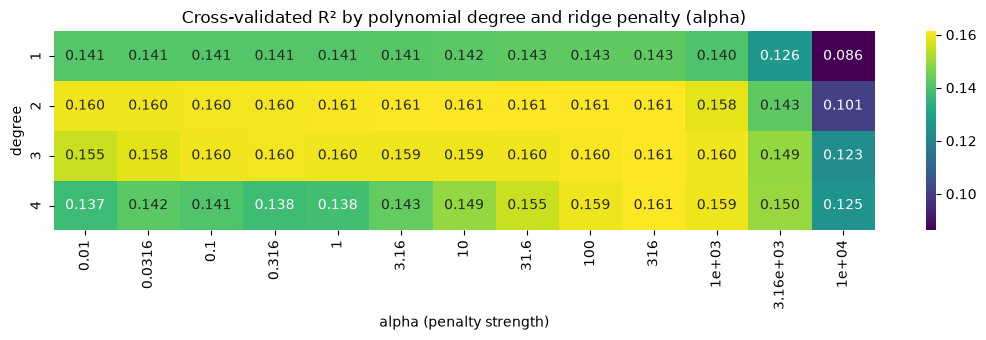

In [18]:
pivot = res.pivot(index="degree", columns="alpha", values="mean_test_r2")
plt.figure(figsize=(11, 3.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis",
            xticklabels=[f"{a:.3g}" for a in pivot.columns])
plt.title("Cross-validated R² by polynomial degree and ridge penalty (alpha)")
plt.xlabel("alpha (penalty strength)"); plt.ylabel("degree")
plt.tight_layout(); plt.show()

Underfitting and overfitting check

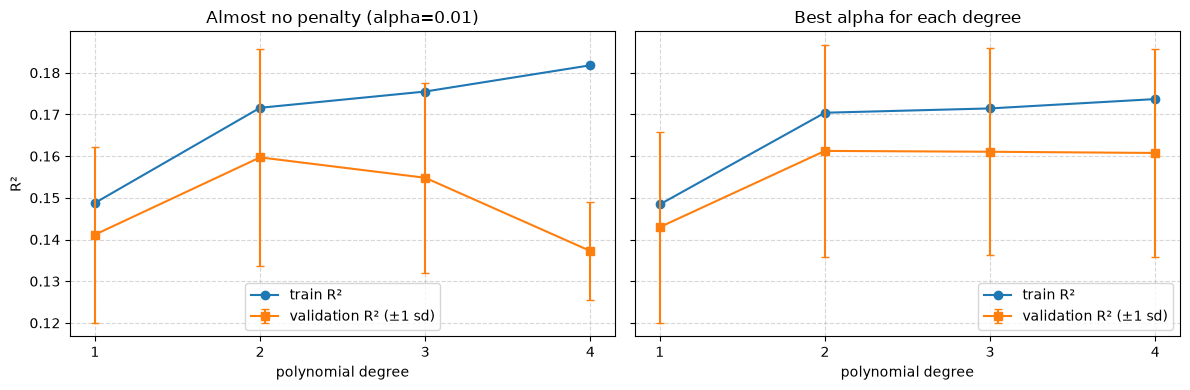

In [19]:
low_alpha = res[res["alpha"] == res["alpha"].min()].sort_values("degree")
best_a = best_per_degree.sort_values("degree")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, d, title in [(axes[0], low_alpha, f"Almost no penalty (alpha={res['alpha'].min():g})"),
                     (axes[1], None, "Best alpha for each degree")]:
    if d is None:
        deg, tr, va, sd = best_a["degree"], best_a["train R2"], best_a["validation R2"], best_a["validation R2 std"]
    else:
        deg, tr, va, sd = d["degree"], d["mean_train_r2"], d["mean_test_r2"], d["std_test_r2"]
    ax.plot(deg, tr, "o-", label="train R²")
    ax.errorbar(deg, va, yerr=sd, fmt="s-", capsize=3, label="validation R² (±1 sd)")
    ax.set_title(title); ax.set_xlabel("polynomial degree"); ax.set_xticks([1, 2, 3, 4])
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
axes[0].set_ylabel("R²")
plt.tight_layout(); plt.show()

Final Test set evaluation

In [20]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
ols = LinearRegression().fit(X_train, y_train)
best_poly = grid.best_estimator_           

def test_metrics(name, est):
    p = est.predict(X_test)
    return {"model": name, "test R2": r2_score(y_test, p),
            "test RMSE": np.sqrt(mean_squared_error(y_test, p)),
            "test MAE": mean_absolute_error(y_test, p)}

test_table = pd.DataFrame([
    test_metrics("Mean predictor (dummy)", dummy),
    test_metrics("Linear regression (OLS)", ols),
    test_metrics(f"Polynomial ridge (deg={grid.best_params_['poly__degree']}, "
                 f"alpha={grid.best_params_['ridge__alpha']:.3g})", best_poly),
])
test_table

,model,test R2,test RMSE,test MAE
0,Mean predictor (dummy),-0.000208,5.326571,4.152381
1,Linear regression (OLS),0.133452,4.957911,3.864613
2,"Polynomial ridge (deg=2, alpha=100)",0.147668,4.917077,3.801104


Bootstraps confidence interval

In [21]:
rng = np.random.default_rng(RANDOM_STATE)
pred_test = best_poly.predict(X_test)
yt = y_test.to_numpy()
boot_r2, boot_rmse = [], []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    boot_r2.append(r2_score(yt[idx], pred_test[idx]))
    boot_rmse.append(np.sqrt(mean_squared_error(yt[idx], pred_test[idx])))
r2_lo, r2_hi = np.percentile(boot_r2, [2.5, 97.5])
rmse_lo, rmse_hi = np.percentile(boot_rmse, [2.5, 97.5])
print(f"Test R2   95% CI: [{r2_lo:.3f}, {r2_hi:.3f}]")
print(f"Test RMSE 95% CI: [{rmse_lo:.3f}, {rmse_hi:.3f}]")

Test R2   95% CI: [0.092, 0.197]
Test RMSE 95% CI: [4.656, 5.188]


Learning curve

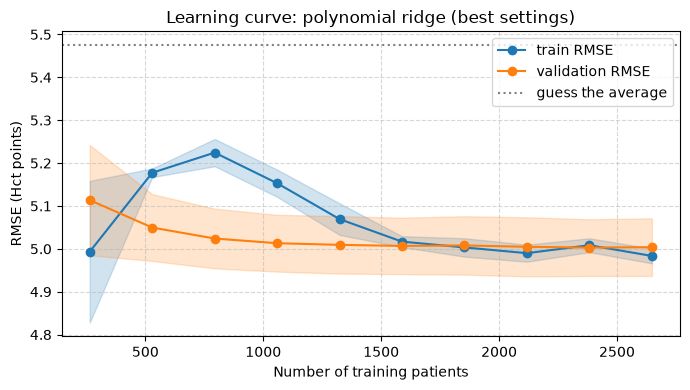

In [ ]:
from sklearn.model_selection import learning_curve

sizes, tr_sc, va_sc = learning_curve(
    best_poly, X_train, y_train, cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
tr_rmse, va_rmse = -tr_sc, -va_sc
dummy_rmse = base_table.loc[0, "CV RMSE mean"]    

plt.figure(figsize=(7, 4))
for vals, label, color in [(tr_rmse, "train RMSE", "tab:blue"), (va_rmse, "validation RMSE", "tab:orange")]:
    m, s = vals.mean(axis=1), vals.std(axis=1)
    plt.plot(sizes, m, "o-", color=color, label=label)
    plt.fill_between(sizes, m - s, m + s, color=color, alpha=0.2)
plt.axhline(dummy_rmse, color="gray", linestyle=":", label="guess the average")
plt.xlabel("Number of training patients"); plt.ylabel("RMSE (Hct points)")
plt.title("Learning curve: polynomial ridge (best settings)")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.tight_layout(); plt.show()

Loss against penalty strength

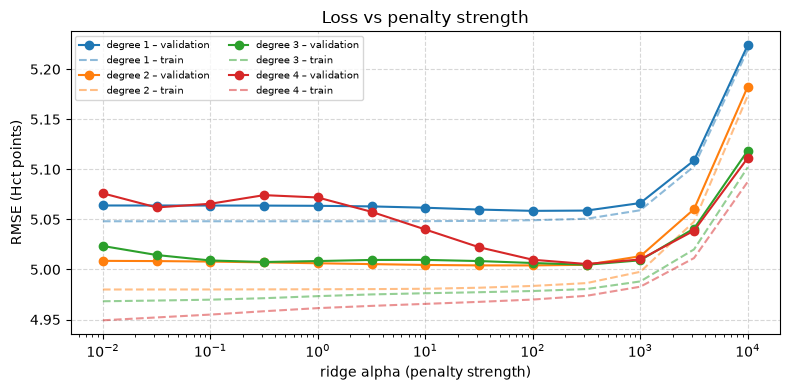

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
for d, color in zip([1, 2, 3, 4], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    sub = res[res["degree"] == d].sort_values("alpha")
    ax.plot(sub["alpha"], -sub["mean_test_rmse"], "o-", color=color, label=f"degree {d} – validation")
    ax.plot(sub["alpha"], -sub["mean_train_rmse"], "--", color=color, alpha=0.5, label=f"degree {d} – train")
ax.set_xscale("log"); ax.set_xlabel("ridge alpha (penalty strength)"); ax.set_ylabel("RMSE (Hct points)")
ax.set_title("Loss vs penalty strength"); ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

# Visualisation

Predictions and residuals

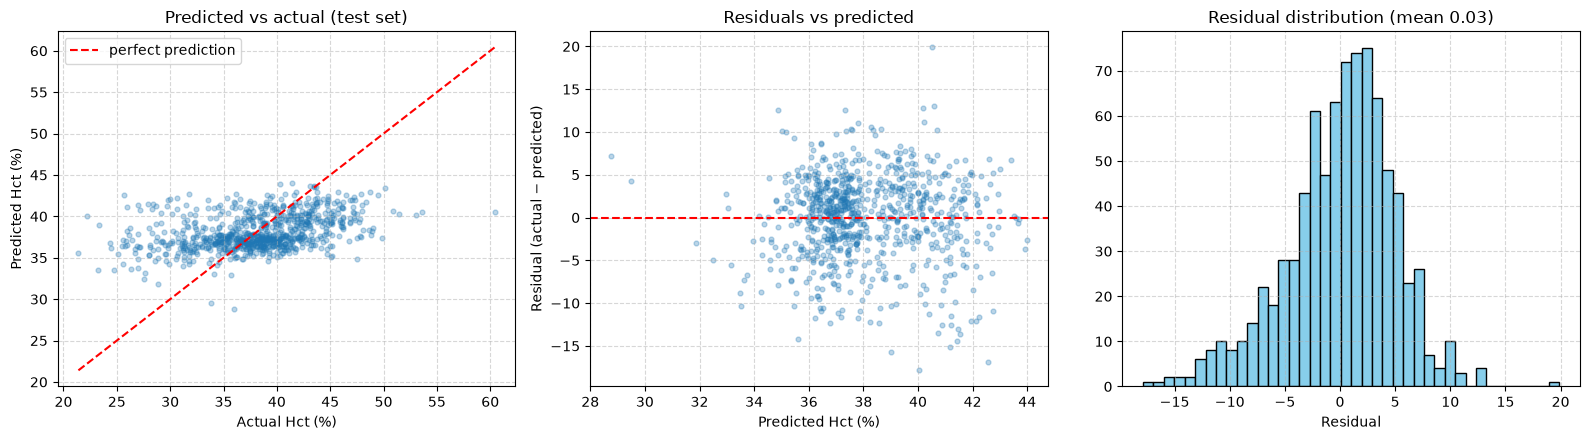

In [24]:
resid = yt - pred_test
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(yt, pred_test, alpha=0.3, s=12)
lim = [min(yt.min(), pred_test.min()), max(yt.max(), pred_test.max())]
axes[0].plot(lim, lim, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual Hct (%)"); axes[0].set_ylabel("Predicted Hct (%)")
axes[0].set_title("Predicted vs actual (test set)"); axes[0].legend()

axes[1].scatter(pred_test, resid, alpha=0.3, s=12)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted Hct (%)"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs predicted")

axes[2].hist(resid, bins=40, color="skyblue", edgecolor="black")
axes[2].set_xlabel("Residual"); axes[2].set_title(f"Residual distribution (mean {resid.mean():.2f})")
for a in axes: a.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

Model Comparisons

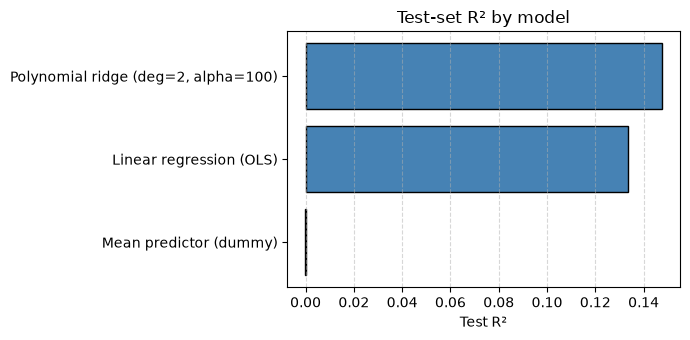

In [25]:
plt.figure(figsize=(7, 3.5))
plt.barh(test_table["model"], test_table["test R2"], color="steelblue", edgecolor="black")
plt.xlabel("Test R²"); plt.title("Test-set R² by model"); plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# Insight interpretation

Feature Importance

,feature,R2 drop when shuffled,std
3,weight,0.062803,0.017105
2,sex_bin,0.060932,0.012740
0,bmi,0.060437,0.009981
1,height,0.005919,0.003306


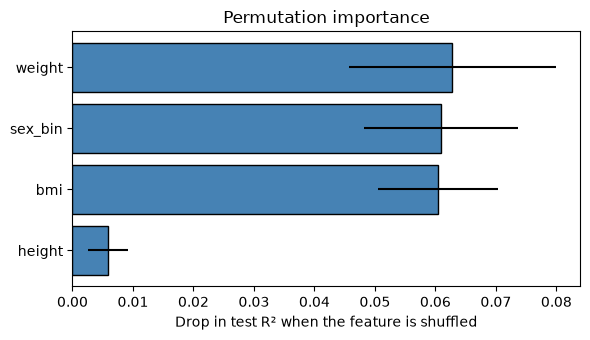

In [26]:
perm = permutation_importance(best_poly, X_test, y_test, scoring="r2",
                              n_repeats=30, random_state=RANDOM_STATE)
perm_df = (pd.DataFrame({"feature": FEATURES, "R2 drop when shuffled": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("R2 drop when shuffled", ascending=False))
display(perm_df)

plt.figure(figsize=(6, 3.5))
plt.barh(perm_df["feature"][::-1], perm_df["R2 drop when shuffled"][::-1],
         xerr=perm_df["std"][::-1], color="steelblue", edgecolor="black")
plt.xlabel("Drop in test R² when the feature is shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.show()

Largest polynomial terms

In [27]:
names = best_poly.named_steps["poly"].get_feature_names_out(FEATURES)
coefs = best_poly.named_steps["ridge"].coef_
coef_df = (pd.DataFrame({"term": names, "coef": coefs})
           .assign(abs_coef=lambda d: d["coef"].abs())
           .sort_values("abs_coef", ascending=False).head(15).drop(columns="abs_coef"))
coef_df

,term,coef
0,bmi,0.857055
3,weight,0.835098
12,sex_bin weight,0.660957
11,sex_bin^2,-0.417324
2,sex_bin,0.417324
7,bmi weight,-0.295965
8,height^2,-0.282787
1,height,0.251580
9,height sex_bin,-0.232386
4,bmi^2,-0.223364


How predicted Hct changes with weight and height

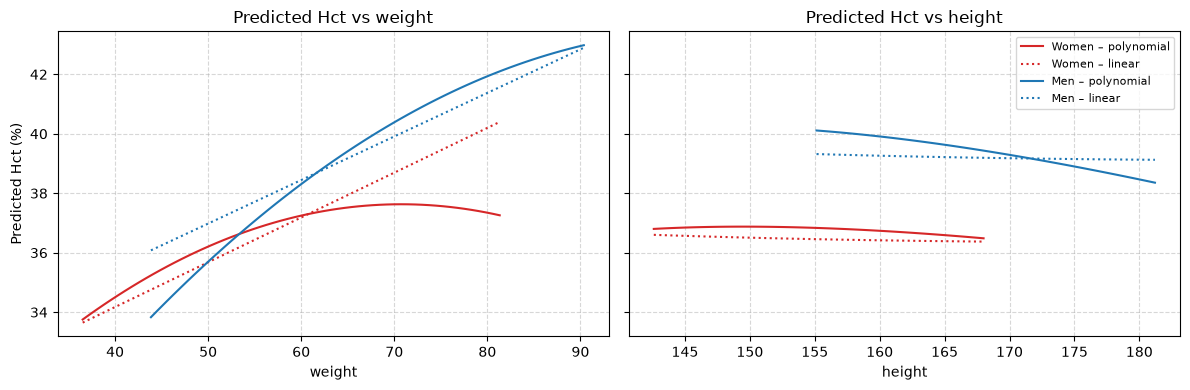

In [28]:
def effect_curve(var, sex_value, n=60):
    sub = model_df[model_df["sex_bin"] == sex_value]
    med = sub[["height", "weight"]].median()
    grid_vals = np.linspace(sub[var].quantile(0.02), sub[var].quantile(0.98), n)
    d = pd.DataFrame({"height": med["height"], "weight": med["weight"],
                      "sex_bin": sex_value}, index=range(n))
    d[var] = grid_vals
    d["bmi"] = d["weight"] / (d["height"] / 100) ** 2
    d = d[FEATURES]
    return grid_vals, best_poly.predict(d), ols.predict(d)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, var in zip(axes, ["weight", "height"]):
    for sex_value, label, color in [(0, "Women", "tab:red"), (1, "Men", "tab:blue")]:
        x_, p_poly, p_ols = effect_curve(var, sex_value)
        ax.plot(x_, p_poly, color=color, label=f"{label} – polynomial")
        ax.plot(x_, p_ols, color=color, linestyle=":", label=f"{label} – linear")
    ax.set_xlabel(var); ax.set_title(f"Predicted Hct vs {var}")
    ax.grid(True, linestyle="--", alpha=0.5)
axes[0].set_ylabel("Predicted Hct (%)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [29]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
rcv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
s_ols  = cross_val_score(LinearRegression(), X_train, y_train, cv=rcv, scoring="r2")
s_poly = cross_val_score(best_poly,          X_train, y_train, cv=rcv, scoring="r2")
diff = s_poly - s_ols
print(f"OLS {s_ols.mean():.3f} | poly {s_poly.mean():.3f} | mean gain {diff.mean():.3f}")
print(f"poly beats OLS in {(diff > 0).mean():.0%} of the 50 folds")

OLS 0.144 | poly 0.163 | mean gain 0.019
poly beats OLS in 96% of the 50 folds


# Ethical Reflection

A model can look fine on average and still work worse for some groups, or fail where it matters clinically.

In [30]:
eval_df = model_df.loc[X_test.index, ["age", "sex", "emop", TARGET]].copy()
eval_df["pred"] = pred_test
eval_df["error"] = eval_df[TARGET] - eval_df["pred"]      # positive = model underestimates Hct
eval_df["age_group"] = pd.cut(eval_df["age"], [0, 40, 60, 75, 120],
                              labels=["<40", "40-59", "60-74", "75+"], right=False)
eval_df["hct_range"] = pd.cut(eval_df[TARGET], [0, 30, 36, 42, 100],
                              labels=["<30 (low)", "30-36", "36-42", ">42"], right=False)

def group_report(col):
    rows = []
    for g, d in eval_df.groupby(col, observed=True):
        rows.append({col: g, "n": len(d),
                     "R2": r2_score(d[TARGET], d["pred"]) if (col != "hct_range" and len(d) > 2) else np.nan,  # R2 is meaningless inside a narrow true-Hct band
                     "RMSE": np.sqrt(mean_squared_error(d[TARGET], d["pred"])),
                     "mean error (actual - pred)": d["error"].mean()})
    return pd.DataFrame(rows).round(3)

for col in ["sex", "age_group", "emop", "hct_range"]:
    display(group_report(col))

,sex,n,R2,RMSE,mean error (actual - pred)
0,F,373,0.095,4.158,0.071
1,M,455,0.095,5.461,0.003


,age_group,n,R2,RMSE,mean error (actual - pred)
0,<40,100,0.152,5.999,0.943
1,40-59,306,0.095,5.201,-0.034
2,60-74,319,0.136,4.275,-0.003
3,75+,103,0.276,4.739,-0.536


,emop,n,R2,RMSE,mean error (actual - pred)
0,0,723,0.131,4.620,0.375
1,1,105,0.022,6.612,-2.319


,hct_range,n,R2,RMSE,mean error (actual - pred)
0,<30 (low),66,NaN,10.171,-9.699
1,30-36,182,NaN,4.636,-3.862
2,36-42,389,NaN,2.451,0.918
3,>42,191,NaN,6.029,5.308
